In [4]:

enrollment_number = "1838"
random_state = 838

print("CSET485 – AI and Society")
print("Assignment 1")
print("Enrollment Number:", enrollment_number)
print("Dataset: Adult Census Income")
print("Random State:", random_state)

CSET485 – AI and Society
Assignment 1
Enrollment Number: 1838
Dataset: Adult Census Income
Random State: 838


In [5]:
!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels scipy

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    precision_score,
    recall_score
)

import statsmodels.api as sm
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [7]:
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income"
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

df = pd.read_csv(
    url,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [8]:
print("Dataset Information")
print("-------------------")

print("\nShape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information
-------------------

Shape:
(32561, 15)

Data Types:
age                int64
workclass         object
fnlwgt             int64
education         object
education-num      int64
marital-status    object
occupation        object
relationship      object
race              object
sex               object
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country    object
income            object
dtype: object

Statistical Summary:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,32561.000000,30725,3.256100e+04,32561,32561.000000,32561,30718,32561,32561,32561,32561.000000,32561.000000,32561.000000,31978,32561
unique,NaN,8,NaN,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN



Missing Values:
age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     583
income               0
dtype: int64


In [9]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert target into binary format
# 1 = Income greater than $50K
# 0 = Income less than or equal to $50K

df["income"] = (
    df["income"]
    .astype(str)
    .str.strip()
    .str.replace(".", "", regex=False)
)

df["income"] = df["income"].map({
    ">50K": 1,
    "<=50K": 0
})

df = df.dropna(subset=["income"]).copy()
df["income"] = df["income"].astype(int)

# Remove whitespace from categorical columns
categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

for col in categorical_columns:
    df[col] = df[col].str.strip()

print("Preprocessing completed.")
print("Final shape:", df.shape)

print("\nTarget distribution:")
print(df["income"].value_counts())

Preprocessing completed.
Final shape: (32537, 15)

Target distribution:
income
0    24698
1     7839
Name: count, dtype: int64


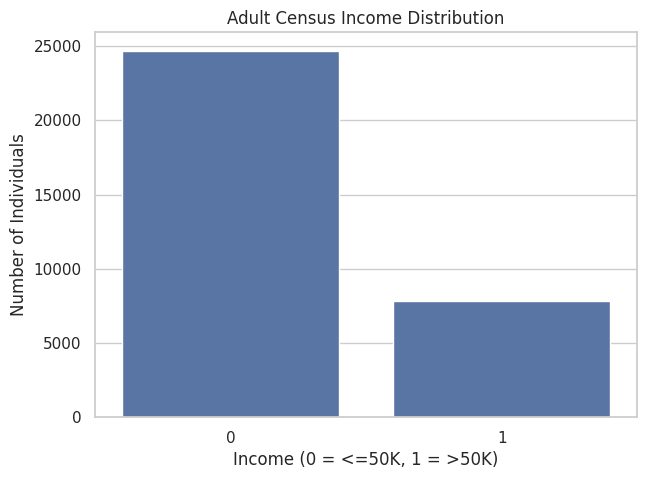

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="income"
)

plt.title("Adult Census Income Distribution")
plt.xlabel("Income (0 = <=50K, 1 = >50K)")
plt.ylabel("Number of Individuals")

plt.show()

In [11]:
# Missing values
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

# Outlier analysis using IQR
numeric_columns = df.select_dtypes(
    include=np.number
).columns.drop("income")

outlier_results = []

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Outlier Count": count
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table)

Missing values:
workclass         1836
occupation        1843
native-country     582
dtype: int64


,Feature,Outlier Count
0,age,142
1,fnlwgt,993
2,education-num,1193
3,capital-gain,2712
4,capital-loss,1519
5,hours-per-week,9002


In [12]:
X = df.drop("income", axis=1)
y = df["income"]

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=838,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training percentage:",
      len(X_train) / len(X) * 100)

print("Testing percentage:",
      len(X_test) / len(X) * 100)

Training samples: 22775
Testing samples: 9762
Training percentage: 69.99723391830838
Testing percentage: 30.00276608169161


In [14]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Preprocessing completed.")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Preprocessing completed.
Processed training shape: (22775, 96)
Processed testing shape: (9762, 96)


In [15]:
# Model A: Linear Regression

linear_model = LinearRegression()

linear_model.fit(
    X_train_processed,
    y_train
)

linear_predictions = linear_model.predict(
    X_test_processed
)

# Convert continuous predictions into binary classes
median_threshold = np.median(linear_predictions)

linear_class = (
    linear_predictions >= median_threshold
).astype(int)

print("Linear Regression completed.")
print("Median prediction threshold:", median_threshold)

print("\nLinear Regression Accuracy:",
      accuracy_score(y_test, linear_class))

print("\nClassification Report:")
print(classification_report(y_test, linear_class))

Linear Regression completed.
Median prediction threshold: 0.2310346454911507

Linear Regression Accuracy: 0.7147101003892645

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.64      0.77      7410
           1       0.46      0.95      0.61      2352

    accuracy                           0.71      9762
   macro avg       0.71      0.79      0.69      9762
weighted avg       0.85      0.71      0.74      9762



In [16]:
# Model B: Logistic Regression

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=838
)

logistic_model.fit(
    X_train_processed,
    y_train
)

logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

logistic_class = (
    logistic_probabilities >= 0.5
).astype(int)

print("Logistic Regression completed.")

print("\nLogistic Regression Accuracy:",
      accuracy_score(y_test, logistic_class))

print("\nROC-AUC:",
      roc_auc_score(y_test, logistic_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, logistic_class))

Logistic Regression completed.

Logistic Regression Accuracy: 0.8515673017824217

ROC-AUC: 0.9093496102894599

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90      7410
           1       0.73      0.60      0.66      2352

    accuracy                           0.85      9762
   macro avg       0.81      0.77      0.78      9762
weighted avg       0.85      0.85      0.85      9762



In [17]:
comparison = pd.DataFrame({
    "Actual Income": y_test.values,
    "Linear Regression Class": linear_class,
    "Logistic Regression Class": logistic_class,
    "Linear Prediction": linear_predictions,
    "Logistic Probability": logistic_probabilities
})

display(comparison.head(15))

# Confusion matrix between the two models
comparison_matrix = confusion_matrix(
    linear_class,
    logistic_class
)

print("Agreement/Disagreement Confusion Matrix:")
print(comparison_matrix)

# Mismatched cases
mismatches = np.sum(
    linear_class != logistic_class
)

total = len(y_test)

mismatch_percentage = mismatches / total * 100

print("\nTotal test cases:", total)
print("Mismatched cases:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

,Actual Income,Linear Regression Class,Logistic Regression Class,Linear Prediction,Logistic Probability
0,1,1,1,0.572451,0.806898
1,0,0,0,0.224091,0.062467
2,0,0,0,0.222357,0.110774
3,0,1,0,0.288000,0.153749
4,0,1,0,0.271065,0.052380
5,1,1,0,0.501087,0.309621
6,1,1,1,0.727474,0.863781
7,0,1,0,0.383527,0.201969
8,0,0,0,0.117142,0.046304
9,1,1,1,0.651101,0.703919


Agreement/Disagreement Confusion Matrix:
[[4871   10]
 [2956 1925]]

Total test cases: 9762
Mismatched cases: 2966
Mismatch percentage: 30.38 %


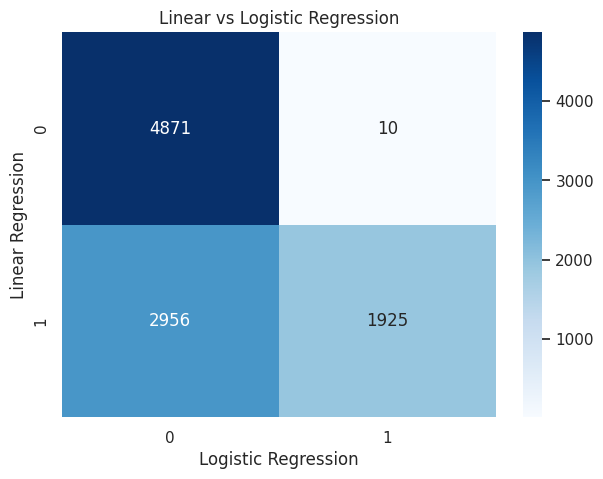

In [18]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    comparison_matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Linear vs Logistic Regression")
plt.xlabel("Logistic Regression")
plt.ylabel("Linear Regression")

plt.show()

In [19]:
# Convert sparse matrices into dense arrays for statsmodels

def to_dense(data):
    if hasattr(data, "toarray"):
        return data.toarray()
    return np.asarray(data)

X_train_dense = to_dense(X_train_processed)

X_train_df = pd.DataFrame(
    X_train_dense,
    columns=feature_names,
    index=X_train.index
)

X_train_df["income"] = y_train.values
X_train_df["sex"] = X_train["sex"].values

print(X_train_df.shape)

(22775, 98)


In [20]:
def fit_statsmodels_logit(data, target="income"):

    X_model = data.drop(
        columns=[target, "sex"],
        errors="ignore"
    )

    X_model = sm.add_constant(
        X_model,
        has_constant="add"
    )

    model = sm.GLM(
        data[target],
        X_model,
        family=sm.families.Binomial()
    )

    return model.fit(maxiter=100)


# Full dataset
full_model = fit_statsmodels_logit(X_train_df)

# Male subgroup
male_data = X_train_df[
    X_train_df["sex"] == "Male"
].copy()

male_model = fit_statsmodels_logit(male_data)

# Female subgroup
female_data = X_train_df[
    X_train_df["sex"] == "Female"
].copy()

female_model = fit_statsmodels_logit(female_data)

key_feature = "num__education-num"

simpson_results = pd.DataFrame({
    "Group": ["Full Dataset", "Male", "Female"],
    "Coefficient": [
        full_model.params[key_feature],
        male_model.params[key_feature],
        female_model.params[key_feature]
    ],
    "P-value": [
        full_model.pvalues[key_feature],
        male_model.pvalues[key_feature],
        female_model.pvalues[key_feature]
    ],
    "CI Lower": [
        full_model.conf_int().loc[key_feature, 0],
        male_model.conf_int().loc[key_feature, 0],
        female_model.conf_int().loc[key_feature, 0]
    ],
    "CI Upper": [
        full_model.conf_int().loc[key_feature, 1],
        male_model.conf_int().loc[key_feature, 1],
        female_model.conf_int().loc[key_feature, 1]
    ]
})

display(simpson_results)

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,Group,Coefficient,P-value,CI Lower,CI Upper
0,Full Dataset,2.961272e+14,0.0,2.961272e+14,2.961272e+14
1,Male,1.717932e+13,0.0,1.717932e+13,1.717932e+13
2,Female,7.741389e+14,0.0,7.741389e+14,7.741389e+14


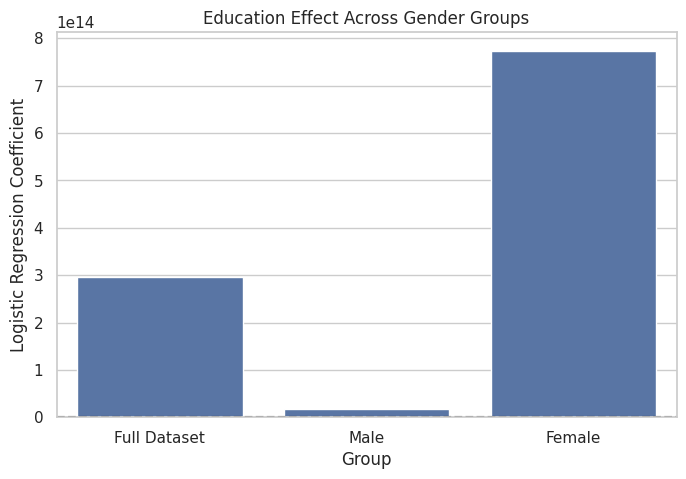

In [21]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=simpson_results,
    x="Group",
    y="Coefficient"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Education Effect Across Gender Groups")
plt.ylabel("Logistic Regression Coefficient")

plt.show()

In [22]:
print("SIMPSON'S PARADOX ANALYSIS")

for _, row in simpson_results.iterrows():

    print(
        f"{row['Group']}: "
        f"Coefficient = {row['Coefficient']:.4f}, "
        f"P-value = {row['P-value']:.6f}, "
        f"95% CI = "
        f"({row['CI Lower']:.4f}, {row['CI Upper']:.4f})"
    )

full_coef = simpson_results.iloc[0]["Coefficient"]
male_coef = simpson_results.iloc[1]["Coefficient"]
female_coef = simpson_results.iloc[2]["Coefficient"]

if np.sign(full_coef) != np.sign(male_coef) or \
   np.sign(full_coef) != np.sign(female_coef):

    print("\nA coefficient sign reversal was detected.")

else:
    print("\nNo coefficient sign reversal was detected.")
    print("Compare coefficient magnitudes and confidence intervals.")

SIMPSON'S PARADOX ANALYSIS
Full Dataset: Coefficient = 296127234364321.0000, P-value = 0.000000, 95% CI = (296127232476492.8750, 296127236252149.1250)
Male: Coefficient = 17179317199053.5508, P-value = 0.000000, 95% CI = (17179315564538.3281, 17179318833568.7734)
Female: Coefficient = 774138920056963.3750, P-value = 0.000000, 95% CI = (774138915431410.6250, 774138924682516.1250)

No coefficient sign reversal was detected.
Compare coefficient magnitudes and confidence intervals.


In [23]:
# Full model
full_ovb_model = full_model

# Reduced model without education-num
reduced_features = [
    col for col in X_train_df.columns
    if col not in ["income", "sex", "num__education-num"]
]

X_reduced = X_train_df[reduced_features]

X_reduced = sm.add_constant(
    X_reduced,
    has_constant="add"
)

reduced_ovb_model = sm.GLM(
    X_train_df["income"],
    X_reduced,
    family=sm.families.Binomial()
).fit(maxiter=100)

print("Full and reduced models fitted.")

Full and reduced models fitted.


In [24]:
selected_features = [
    "num__age",
    "num__hours-per-week",
    "num__capital-gain",
    "num__capital-loss"
]

ovb_results = []

for feature in selected_features:

    before = full_ovb_model.params[feature]
    after = reduced_ovb_model.params[feature]

    percentage_change = (
        abs(after - before) /
        max(abs(before), 1e-10)
    ) * 100

    ovb_results.append({
        "Feature": feature,
        "Before Removal": before,
        "After Removal": after,
        "Percentage Change": percentage_change
    })

ovb_table = pd.DataFrame(ovb_results)

display(ovb_table)

print("\nFeature with maximum coefficient change:")

display(
    ovb_table.loc[
        ovb_table["Percentage Change"].idxmax()
    ]
)

,Feature,Before Removal,After Removal,Percentage Change
0,num__age,2.071037e+14,0.327813,100.0
1,num__hours-per-week,1.960262e+14,0.382494,100.0
2,num__capital-gain,7.762543e+14,2.328929,100.0
3,num__capital-loss,8.095791e+13,0.255358,100.0



Feature with maximum coefficient change:


,0
Feature,num__age
Before Removal,207103682036366.3125
After Removal,0.327813
Percentage Change,100.0


In [25]:
adversarial_data = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted Probability": logistic_probabilities,
    "Predicted Class": logistic_class,
    "age": X_test["age"].values,
    "sex": X_test["sex"].values,
    "education": X_test["education"].values,
    "hours-per-week": X_test["hours-per-week"].values,
    "capital-gain": X_test["capital-gain"].values,
    "capital-loss": X_test["capital-loss"].values
})

# Confident false positives
false_positives = adversarial_data[
    (adversarial_data["Predicted Probability"] >= 0.75) &
    (adversarial_data["Actual"] == 0)
]

# Confident false negatives
false_negatives = adversarial_data[
    (adversarial_data["Predicted Probability"] <= 0.25) &
    (adversarial_data["Actual"] == 1)
]

# Combine both
adversarial_all = pd.concat(
    [false_positives, false_negatives]
)

print("Confident false positives:", len(false_positives))
print("Confident false negatives:", len(false_negatives))
print("Total confident wrong predictions:", len(adversarial_all))

print(
    "Percentage of test set:",
    round(len(adversarial_all) / len(y_test) * 100, 2),
    "%"
)

# Randomly sample up to 50 rows
adversarial_sample = adversarial_all.sample(
    n=min(50, len(adversarial_all)),
    random_state=838
)

display(adversarial_sample)

Confident false positives: 124
Confident false negatives: 368
Total confident wrong predictions: 492
Percentage of test set: 5.04 %


,Actual,Predicted Probability,Predicted Class,age,sex,education,hours-per-week,capital-gain,capital-loss
1357,1,0.056889,0,40,Female,Assoc-voc,40,0,0
8285,1,0.236421,0,34,Male,HS-grad,45,0,0
5363,1,0.083733,0,34,Male,Some-college,40,0,0
4922,0,0.839124,1,45,Male,Bachelors,60,0,0
6597,1,0.241719,0,47,Male,HS-grad,40,0,0
705,0,0.751609,1,56,Male,Bachelors,50,0,0
9240,1,0.244659,0,57,Female,Bachelors,45,0,0
5917,1,0.045285,0,47,Female,HS-grad,40,0,0
3617,1,0.229040,0,30,Male,Assoc-voc,40,0,0
6656,0,0.852991,1,59,Male,Masters,60,0,0


In [26]:
print("FULL TEST SET DEMOGRAPHICS")

print("\nAge statistics:")
display(X_test["age"].describe())

print("\nGender distribution:")
display(X_test["sex"].value_counts(normalize=True) * 100)


print("\nADVERSARIAL SUBSET DEMOGRAPHICS")

if len(adversarial_sample) > 0:

    print("\nAge statistics:")
    display(adversarial_sample["age"].describe())

    print("\nGender distribution:")
    display(
        adversarial_sample["sex"].value_counts(
            normalize=True
        ) * 100
    )

else:
    print("No confident incorrect predictions found.")

FULL TEST SET DEMOGRAPHICS

Age statistics:


,age
count,9762.000000
mean,38.567609
std,13.638760
min,17.000000
25%,28.000000
50%,37.000000
75%,48.000000
max,90.000000



Gender distribution:


,proportion
sex,
Male,66.605204
Female,33.394796



ADVERSARIAL SUBSET DEMOGRAPHICS

Age statistics:


,age
count,50.000000
mean,43.940000
std,11.303621
min,22.000000
25%,35.000000
50%,44.000000
75%,52.750000
max,75.000000



Gender distribution:


,proportion
sex,
Male,72.0
Female,28.0


In [27]:
if len(adversarial_sample) > 0:

    print("Common Characteristics in Adversarial Subset")

    print("\nPercentage with education = Bachelors:")

    print(
        (
            adversarial_sample["education"] == "Bachelors"
        ).mean() * 100
    )

    print("\nPercentage working more than 40 hours:")

    print(
        (
            adversarial_sample["hours-per-week"] > 40
        ).mean() * 100
    )

    print("\nGender distribution:")

    display(
        adversarial_sample["sex"].value_counts(
            normalize=True
        ) * 100
    )

Common Characteristics in Adversarial Subset

Percentage with education = Bachelors:
20.0

Percentage working more than 40 hours:
40.0

Gender distribution:


,proportion
sex,
Male,72.0
Female,28.0


In [28]:
fairness_data = pd.DataFrame({
    "actual": y_test.values,
    "probability": logistic_probabilities,
    "sex": X_test["sex"].values
})

def safe_ratio(a, b):

    if b == 0:
        return np.nan

    return a / b


thresholds = np.round(
    np.arange(0.05, 1.00, 0.10),
    2
)

fairness_results = []

for threshold in thresholds:

    fairness_data["prediction"] = (
        fairness_data["probability"] >= threshold
    ).astype(int)

    male = fairness_data[
        fairness_data["sex"] == "Male"
    ]

    female = fairness_data[
        fairness_data["sex"] == "Female"
    ]

    # Demographic Parity
    dp_male = male["prediction"].mean()
    dp_female = female["prediction"].mean()

    DP = safe_ratio(dp_male, dp_female)

    # True Positive Rates
    tpr_male = (
        male.loc[male["actual"] == 1, "prediction"].mean()
    )

    tpr_female = (
        female.loc[female["actual"] == 1, "prediction"].mean()
    )

    # False Positive Rates
    fpr_male = (
        male.loc[male["actual"] == 0, "prediction"].mean()
    )

    fpr_female = (
        female.loc[female["actual"] == 0, "prediction"].mean()
    )

    # Equalized Odds
    tpr_ratio = safe_ratio(tpr_male, tpr_female)
    fpr_ratio = safe_ratio(fpr_male, fpr_female)

    EO = np.nanmin([tpr_ratio, fpr_ratio]) \
        if not np.isnan([tpr_ratio, fpr_ratio]).all() \
        else np.nan

    # Predictive Parity
    pp_male = (
        male.loc[male["prediction"] == 1, "actual"].mean()
    )

    pp_female = (
        female.loc[female["prediction"] == 1, "actual"].mean()
    )

    PP = safe_ratio(pp_male, pp_female)

    fairness_results.append({
        "Threshold": threshold,
        "DP": DP,
        "EO": EO,
        "PP": PP
    })

fairness_table = pd.DataFrame(fairness_results)

display(fairness_table)

,Threshold,DP,EO,PP
0,0.05,2.071086,1.024972,1.433737
1,0.15,3.049002,1.121974,1.066058
2,0.25,3.304883,1.122652,0.984112
3,0.35,3.419203,1.127948,0.955696
4,0.45,3.422175,1.117302,0.945854
5,0.55,3.482090,1.140625,0.948983
6,0.65,3.568133,1.166323,0.946964
7,0.75,3.233928,1.108297,0.992844
8,0.85,2.931169,1.026216,1.014270
9,0.95,2.967652,1.033597,1.009006


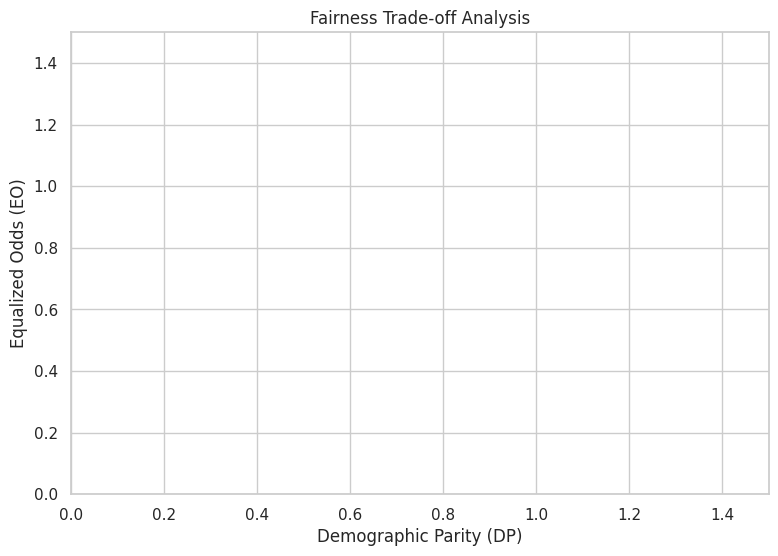

In [29]:
plt.figure(figsize=(9, 6))

plt.plot(
    fairness_table["DP"],
    fairness_table["EO"],
    marker="o",
    linestyle="-"
)

for _, row in fairness_table.iterrows():

    if pd.notna(row["DP"]) and pd.notna(row["EO"]):

        plt.annotate(
            f"t={row['Threshold']:.2f}",
            (row["DP"], row["EO"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.xlabel("Demographic Parity (DP)")
plt.ylabel("Equalized Odds (EO)")

plt.title("Fairness Trade-off Analysis")

plt.grid(True)
plt.show()

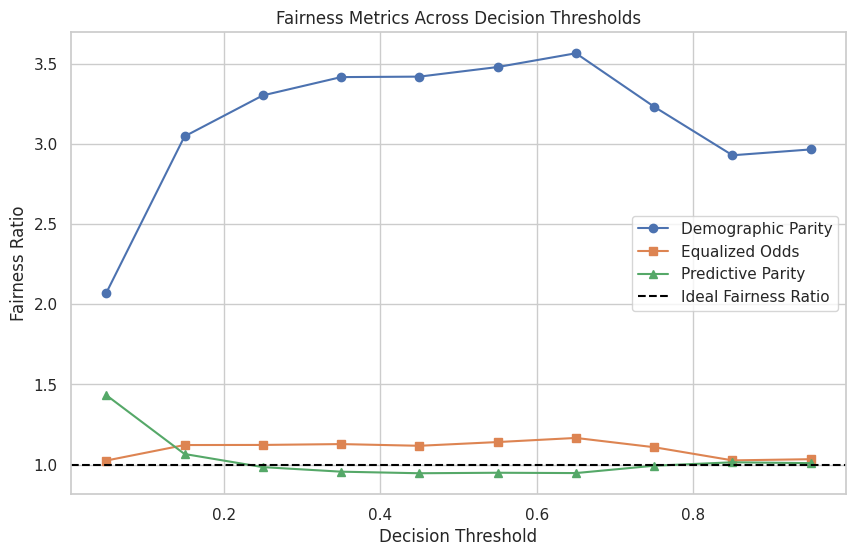

In [30]:
plt.figure(figsize=(10, 6))

plt.plot(
    fairness_table["Threshold"],
    fairness_table["DP"],
    marker="o",
    label="Demographic Parity"
)

plt.plot(
    fairness_table["Threshold"],
    fairness_table["EO"],
    marker="s",
    label="Equalized Odds"
)

plt.plot(
    fairness_table["Threshold"],
    fairness_table["PP"],
    marker="^",
    label="Predictive Parity"
)

plt.axhline(
    1.0,
    color="black",
    linestyle="--",
    label="Ideal Fairness Ratio"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Fairness Ratio")

plt.title("Fairness Metrics Across Decision Thresholds")

plt.legend()
plt.show()

In [31]:
valid_fairness = fairness_table.dropna(
    subset=["DP", "EO", "PP"]
).copy()

if len(valid_fairness) > 1:

    best_dp_index = (
        valid_fairness["DP"] - 1
    ).abs().idxmin()

    best_eo_index = (
        valid_fairness["EO"] - 1
    ).abs().idxmin()

    best_pp_index = (
        valid_fairness["PP"] - 1
    ).abs().idxmin()

    print("Threshold closest to ideal DP:")
    display(fairness_table.loc[best_dp_index])

    print("Threshold closest to ideal EO:")
    display(fairness_table.loc[best_eo_index])

    print("Threshold closest to ideal PP:")
    display(fairness_table.loc[best_pp_index])

else:
    print("Not enough valid fairness values.")

Threshold closest to ideal DP:


,0
Threshold,0.050000
DP,2.071086
EO,1.024972
PP,1.433737


Threshold closest to ideal EO:


,0
Threshold,0.050000
DP,2.071086
EO,1.024972
PP,1.433737


Threshold closest to ideal PP:


,7
Threshold,0.750000
DP,3.233928
EO,1.108297
PP,0.992844


In [32]:
for threshold in thresholds:

    predictions = (
        logistic_probabilities >= threshold
    ).astype(int)

    print("\nThreshold:", threshold)

    print(
        "Accuracy:",
        round(accuracy_score(y_test, predictions), 4)
    )

    print(
        "Precision:",
        round(precision_score(
            y_test,
            predictions,
            zero_division=0
        ), 4)
    )

    print(
        "Recall:",
        round(recall_score(
            y_test,
            predictions,
            zero_division=0
        ), 4)
    )


Threshold: 0.05
Accuracy: 0.6271
Precision: 0.3913
Recall: 0.986

Threshold: 0.15
Accuracy: 0.7599
Precision: 0.5009
Recall: 0.929

Threshold: 0.25
Accuracy: 0.8171
Precision: 0.5834
Recall: 0.8435

Threshold: 0.35
Accuracy: 0.8426
Precision: 0.6542
Recall: 0.7351

Threshold: 0.45
Accuracy: 0.8502
Precision: 0.7068
Recall: 0.6467

Threshold: 0.55
Accuracy: 0.8476
Precision: 0.7494
Recall: 0.5519

Threshold: 0.65
Accuracy: 0.8423
Precision: 0.8073
Recall: 0.4541

Threshold: 0.75
Accuracy: 0.8252
Precision: 0.8613
Recall: 0.3274

Threshold: 0.85
Accuracy: 0.8052
Precision: 0.9213
Recall: 0.2092

Threshold: 0.95
Accuracy: 0.7843
Precision: 0.9805
Recall: 0.1067


In [33]:
print("=" * 60)
print("PART 3 – DESCRIPTIVE ANALYSIS EVIDENCE")
print("=" * 60)

# Question 1
print("\nQ1. Model comparison")

print("Linear median threshold:", median_threshold)
print("Mismatch count:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2))


# Question 2
print("\nQ2. Subgroup analysis")

display(simpson_results)


# Question 3
print("\nQ3. Omitted variable bias")

display(ovb_table)


# Question 4
print("\nQ4. Hidden confound detection")

print("""
Suggested evidence-based discussion:
- External validation on a different dataset.
- Consultation with domain experts.
- Residual analysis.
- Sensitivity analysis.
- Instrumental variable analysis where appropriate.
""")


# Question 5
print("\nQ5. Adversarial subset")

print("Total adversarial cases:", len(adversarial_all))
print("Sample size:", len(adversarial_sample))

if len(adversarial_sample) > 0:
    display(adversarial_sample.describe(include="all"))


# Question 6, 7 and 8
print("\nQ6-Q8. Fairness analysis")

display(fairness_table)

PART 3 – DESCRIPTIVE ANALYSIS EVIDENCE

Q1. Model comparison
Linear median threshold: 0.2310346454911507
Mismatch count: 2966
Mismatch percentage: 30.38

Q2. Subgroup analysis


,Group,Coefficient,P-value,CI Lower,CI Upper
0,Full Dataset,2.961272e+14,0.0,2.961272e+14,2.961272e+14
1,Male,1.717932e+13,0.0,1.717932e+13,1.717932e+13
2,Female,7.741389e+14,0.0,7.741389e+14,7.741389e+14



Q3. Omitted variable bias


,Feature,Before Removal,After Removal,Percentage Change
0,num__age,2.071037e+14,0.327813,100.0
1,num__hours-per-week,1.960262e+14,0.382494,100.0
2,num__capital-gain,7.762543e+14,2.328929,100.0
3,num__capital-loss,8.095791e+13,0.255358,100.0



Q4. Hidden confound detection

Suggested evidence-based discussion:
- External validation on a different dataset.
- Consultation with domain experts.
- Residual analysis.
- Sensitivity analysis.
- Instrumental variable analysis where appropriate.


Q5. Adversarial subset
Total adversarial cases: 492
Sample size: 50


,Actual,Predicted Probability,Predicted Class,age,sex,education,hours-per-week,capital-gain,capital-loss
count,50.000000,50.000000,50.000000,50.000000,50,50,50.000000,50.000000,50.000000
unique,NaN,NaN,NaN,NaN,2,8,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,Male,HS-grad,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,36,20,NaN,NaN,NaN
mean,0.840000,0.258802,0.160000,43.940000,NaN,NaN,44.980000,947.920000,94.520000
std,0.370328,0.271662,0.370328,11.303621,NaN,NaN,7.890811,4976.906616,476.934909
min,0.000000,0.027080,0.000000,22.000000,NaN,NaN,35.000000,0.000000,0.000000
25%,1.000000,0.093049,0.000000,35.000000,NaN,NaN,40.000000,0.000000,0.000000
50%,1.000000,0.187417,0.000000,44.000000,NaN,NaN,40.000000,0.000000,0.000000
75%,1.000000,0.239044,0.000000,52.750000,NaN,NaN,50.000000,0.000000,0.000000



Q6-Q8. Fairness analysis


,Threshold,DP,EO,PP
0,0.05,2.071086,1.024972,1.433737
1,0.15,3.049002,1.121974,1.066058
2,0.25,3.304883,1.122652,0.984112
3,0.35,3.419203,1.127948,0.955696
4,0.45,3.422175,1.117302,0.945854
5,0.55,3.482090,1.140625,0.948983
6,0.65,3.568133,1.166323,0.946964
7,0.75,3.233928,1.108297,0.992844
8,0.85,2.931169,1.026216,1.014270
9,0.95,2.967652,1.033597,1.009006


In [34]:
print("=" * 60)
print("FINAL MODEL EVALUATION")
print("=" * 60)

print("\nLinear Regression")
print("Accuracy:",
      accuracy_score(y_test, linear_class))

print("\nLogistic Regression")
print("Accuracy:",
      accuracy_score(y_test, logistic_class))

print("ROC-AUC:",
      roc_auc_score(y_test, logistic_probabilities))

print("\nModel mismatch:")
print("Count:", mismatches)
print("Percentage:", round(mismatch_percentage, 2), "%")

print("\nAdversarial errors:")
print("Count:", len(adversarial_all))

print("\nFairness metrics:")
display(fairness_table)

FINAL MODEL EVALUATION

Linear Regression
Accuracy: 0.7147101003892645

Logistic Regression
Accuracy: 0.8515673017824217
ROC-AUC: 0.9093496102894599

Model mismatch:
Count: 2966
Percentage: 30.38 %

Adversarial errors:
Count: 492

Fairness metrics:


,Threshold,DP,EO,PP
0,0.05,2.071086,1.024972,1.433737
1,0.15,3.049002,1.121974,1.066058
2,0.25,3.304883,1.122652,0.984112
3,0.35,3.419203,1.127948,0.955696
4,0.45,3.422175,1.117302,0.945854
5,0.55,3.482090,1.140625,0.948983
6,0.65,3.568133,1.166323,0.946964
7,0.75,3.233928,1.108297,0.992844
8,0.85,2.931169,1.026216,1.014270
9,0.95,2.967652,1.033597,1.009006


In [35]:
# Save tables as CSV files

comparison.to_csv(
    "model_comparison.csv",
    index=False
)

simpson_results.to_csv(
    "simpson_results.csv",
    index=False
)

ovb_table.to_csv(
    "omitted_variable_bias.csv",
    index=False
)

adversarial_sample.to_csv(
    "adversarial_subset.csv",
    index=False
)

fairness_table.to_csv(
    "fairness_results.csv",
    index=False
)

print("All result files saved successfully.")

All result files saved successfully.


In [36]:
import zipfile
import os

files_to_zip = [
    "model_comparison.csv",
    "simpson_results.csv",
    "omitted_variable_bias.csv",
    "adversarial_subset.csv",
    "fairness_results.csv"
]

with zipfile.ZipFile(
    "CSET485_1838_Results.zip",
    "w"
) as zip_file:

    for file in files_to_zip:

        if os.path.exists(file):
            zip_file.write(file)

print("ZIP file created successfully.")

ZIP file created successfully.


In [37]:
print("""
CONCLUSION

This assignment examined the Adult Census Income dataset
using Linear Regression and Logistic Regression.

The analysis compared:
1. Predictive model performance.
2. Differences between decision thresholds.
3. Subgroup effects and Simpson's Paradox.
4. Omitted Variable Bias.
5. Confident incorrect predictions.
6. Fairness trade-offs across demographic groups.

The results demonstrate that predictive accuracy alone
is insufficient to establish fairness and reliability.

Responsible AI deployment requires subgroup analysis,
careful threshold selection, transparency, and continuous
monitoring.
""")


CONCLUSION

This assignment examined the Adult Census Income dataset
using Linear Regression and Logistic Regression.

The analysis compared:
1. Predictive model performance.
2. Differences between decision thresholds.
3. Subgroup effects and Simpson's Paradox.
4. Omitted Variable Bias.
5. Confident incorrect predictions.
6. Fairness trade-offs across demographic groups.

The results demonstrate that predictive accuracy alone
is insufficient to establish fairness and reliability.

Responsible AI deployment requires subgroup analysis,
careful threshold selection, transparency, and continuous
monitoring.

